###  Cách triển khai mô hình hiện tại:
- **Tuning** sử dụng GridSearchCV để tìm ra parameter tốt nhất(Nhưng đã lượt bớt giảm param_grid dựa vào kinh nghiệm train ở hai notebook trước nhằm giúp train nhanh hơn)
- **Sử dụng k-fold**(k =5) validate để tránh overfiting
- **Xử lý mất cân bằng bằng** linh hoạt tùy vào từng model cụ thể. Sử dụng tham số `class_weight` hoặc `scale_pos_weight` trong mô hình tree-base như RF, XGB, LightGBM, CatBoost. Áp dụng các kỹ thuật resampling như SMOTE hay UnderSampler cho mô hình tuyến tính như logistic regression
- **Tối ưu ngưỡng phân loại (threshold)** đựa trên việc đánh giá F1-score tốt nhất nhằm đánh giá công bằng và phản ánh đúng năng lực mô hình.

---

##  Tối ưu threshold là gì?

Trong các mô hình phân loại như dự đoán vỡ nợ, mô hình trả ra **xác suất** một khách hàng thuộc lớp 1 (vỡ nợ), ví dụ: 0.3, 0.7, 0.9...

- **Threshold (ngưỡng)** là giá trị cắt để chuyển xác suất thành phân loại:
  - Nếu xác suất ≥ 0.5 → dự đoán **vỡ nợ** (class 1)
  - Nếu xác suất < 0.5 → dự đoán **không vỡ nợ** (class 0)

### Tại sao threshold = 0.5 không tối ưu?

- Trong các bài toán mất cân bằng, class 1 (vỡ nợ) thường chiếm tỷ lệ rất nhỏ.
- Ngưỡng 0.5 thường **bỏ sót nhiều khách hàng rủi ro** → Recall thấp.
- Ví dụ: nếu xác suất là 0.3 (mức rủi ro cao), mô hình vẫn dự đoán là "an toàn" nếu giữ ngưỡng 0.5 → **bỏ sót rủi ro**.

---

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 7.2 MB/s eta 0:00:00


In [ ]:
# Import libraries
import os
import gc
from glob import glob
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, LabelEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from tqdm import tqdm
from sklearn.model_selection import ParameterGrid
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, KFold, cross_val_predict, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, classification_report, roc_curve)

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier,StackingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
import catboost as cb
import lightgbm as lgb
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
import copy
import warnings
import time
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)

import joblib

## Data Preprocessing

### Load data

In [ ]:
from google.colab import drive
root_drive='/content/drive'
drive.mount(root_drive, force_remount=True)

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/KhoaLuan/Data/df_cleaned_old_customers.csv', nrows=None)

In [ ]:
df = df.drop(columns=['Unnamed: 0'])
print("Dữ liệu có dạng:", df.shape)
df.head()

Dữ liệu có dạng: (291057, 29)


,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_CNT_PAYMENT_SUM,PREV_APP_CREDIT_PERC_MIN,INST_DPD_MEAN,INST_PAYMENT_DIFF_MEAN,INST_AMT_PAYMENT_MEAN,INST_AMT_INSTALMENT_MAX,POS_MONTHS_BALANCE_SIZE,ORGANIZATION_TYPE,NAME_FAMILY_STATUS,AGE,AGE_GROUP,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_EMPLOYED,YEARS_LAST_PHONE_CHANGE,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS
0,1.0,0.1617,202500.0,406597.5,24700.5,49156.2,108131.945,1681.0289,9251.775,24.0,1.000000,0.000000,0.00000,11559.247,53093.746,19.0,Business Entity,Single,26,25-34,10,6,2.0,3,1.0,2.4,1.4,1.7,0.1
1,0.0,0.4668,270000.0,1293502.5,35698.5,0.0,254350.120,0.0000,56553.990,30.0,0.868825,0.000000,0.00000,64754.586,560835.400,28.0,Other,Married,46,45-54,3,1,3.0,2,1.5,3.8,2.2,2.0,1.5
2,0.0,0.6426,67500.0,135000.0,6750.0,0.0,94518.900,0.0000,5357.250,4.0,1.207699,0.000000,0.00000,7096.155,10573.965,4.0,Unknown,Single,52,45-54,12,7,1.0,2,1.3,2.4,1.5,2.2,2.0
3,0.0,0.6504,135000.0,312682.5,29686.5,44971.6,194400.000,0.0000,23651.174,138.0,0.759418,0.000000,0.00000,62947.090,691786.900,21.0,Business Entity,Married,52,45-54,27,7,8.0,2,0.4,2.9,1.3,0.5,0.0
4,0.0,0.3228,121500.0,513000.0,21865.5,0.0,146250.000,0.0000,12278.805,124.0,0.791139,0.954545,452.38434,12214.060,22678.785,66.0,Culture & Religion,Single,55,55-64,12,9,8.0,3,2.1,3.1,2.1,1.0,0.0


### Split tập train/test trước khi xử lý dữ liệu

In [ ]:
# Tách X, y
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

# Train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
y_train.value_counts()

,count
TARGET,
0.0,213769
1.0,19076


### Feature pipeline

Chỉ tạo preprocessor và fit chỉ trên train

In [ ]:
# Chia cột
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Tiền xử lý
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

## Machine Learning - Modeling

Evaluate Function

In [ ]:
def gini_score(y_true, y_proba):
    return 2 * roc_auc_score(y_true, y_proba) - 1

def evaluate_model(model, X_test, y_test, model_name=None, verbose=True):
    start = time.time()
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    end = time.time()

    cm = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cm.ravel()

    recall = TP / (TP + FN) if (TP + FN) > 0 else 0  # Sensitivity
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    gmean = np.sqrt(recall * specificity)
    auc = roc_auc_score(y_test, y_proba)
    gini = 2 * auc - 1

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Recall (Sensitivity)": recall,
        "Specificity": specificity,
        "G-Mean": gmean,
        "ROC AUC": auc,
        "Gini": gini,
        "Time": round(end - start, 2)
    }

    if verbose:
        print(f"\n Evaluation for {model_name or 'model'}")
        print(f"Accuracy       : {results['Accuracy']:.4f}")
        print(f"F1-score       : {results['F1']:.4f}")
        print(f"Recall         : {results['Recall (Sensitivity)']:.4f}")
        print(f"Specificity    : {results['Specificity']:.4f}")
        print(f"G-Mean         : {results['G-Mean']:.4f}")
        print(f"ROC AUC        : {results['ROC AUC']:.4f}")
        print(f"Gini           : {results['Gini']:.4f}")
        print("Confusion Matrix:\n", cm)
        print("Classification Report:\n", classification_report(y_test, y_pred))
        print(f"Time taken: {results['Time']}s\n")

    return results


## Machine Learning - Hyperparameter Tuning - Optimize Threshold

In [ ]:
save_dir = "/content/drive/MyDrive/KhoaLuan/Models"
os.makedirs(save_dir, exist_ok=True)

In [ ]:
def tune_model_with_cv(X, y, model, model_name, preprocessor,
                       param_grid=None,
                       categorical_features_idx=None,
                       imbalance_strategy="auto",  # "smote", "under", "passthrough", or "auto"
                       search_method="grid",
                       k=5, n_iter=10,
                       optimize_threshold=False):

    print(f"\nTuning {model_name.upper()} using {search_method} search...")

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    # === Xử lý chọn sampler phù hợp ===
    if imbalance_strategy == "auto":
        if model_name.lower() in ["logistic", "logreg", "mlp", "knn"]:
            sampler = SMOTE(random_state=42)
        elif model_name.lower() in ["xgb", "xgboost", "lgbm", "catboost", "rf", "randomforest"]:
            sampler = "passthrough"  # để dùng scale_pos_weight/class_weight bên trong model
        else:
            sampler = "passthrough"
    elif imbalance_strategy == "smote":
        if categorical_features_idx:
            sampler = SMOTENC(categorical_features=categorical_features_idx, random_state=42)
        else:
            sampler = SMOTE(random_state=42)
    elif imbalance_strategy == "under":
        sampler = RandomUnderSampler(random_state=42)
    else:
        sampler = "passthrough"

    # === Khởi tạo pipeline ===
    model_clone = copy.deepcopy(model)
    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("sampler", sampler),
        ("classifier", model_clone)
    ])

    # === Grid hoặc Random search ===
    if param_grid:
        if search_method == "grid":
            search = GridSearchCV(
                pipeline, param_grid,
                scoring="roc_auc",
                cv=skf, n_jobs=-1, verbose=1
            )
        elif search_method == "random":
            search = RandomizedSearchCV(
                pipeline, param_distributions=param_grid,
                n_iter=n_iter, scoring="roc_auc",
                cv=skf, n_jobs=-1, verbose=1,
                random_state=42
            )
        search.fit(X, y)
        best_model = search.best_estimator_
        print(f"Best ROC AUC score: {search.best_score_:.4f}")
        print("Best Parameters:", search.best_params_)
    else:
        best_model = pipeline.fit(X, y)

    # === Optional: tối ưu ngưỡng threshold để tăng F1 ===
    if optimize_threshold:
        print("Optimizing threshold for best F1 score...")
        from sklearn.model_selection import cross_val_predict

        y_probs = cross_val_predict(best_model, X, y, cv=skf,
                                    method="predict_proba", n_jobs=-1)[:, 1]
        thresholds = np.arange(0.1, 0.9, 0.01)
        f1_scores = [f1_score(y, y_probs > t) for t in thresholds]
        best_thresh = thresholds[np.argmax(f1_scores)]
        print(f"Best threshold: {best_thresh:.2f} with F1: {max(f1_scores):.4f}")

        return best_model, best_thresh

    return best_model

### Logistic Regression

In [ ]:
%%time
# 1. Define model + params
logreg_model = LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42)
# Correct the parameter grid name
logreg_param_grid = {'classifier__C': [0.1, 1, 10]}

# 2. Train
logreg_best_model, logreg_best_threshold = tune_model_with_cv(
    X, y,
    model=logreg_model,
    model_name="logistic",
    preprocessor=preprocessor,
    param_grid=logreg_param_grid,
    imbalance_strategy="auto",
    search_method="grid",
    optimize_threshold=True
)




Tuning LOGISTIC using grid search...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best ROC AUC score: 0.7327
Best Parameters: {'classifier__C': 0.1}
Optimizing threshold for best F1 score...
Best threshold: 0.65 with F1: 0.2848
CPU times: user 28.7 s, sys: 1.09 s, total: 29.8 s
Wall time: 4min 37s


In [ ]:
# 3. Evaluate on test set
logreg_result = evaluate_model(logreg_best_model, X_test_raw, y_test, model_name="Logistic Regression")

joblib.dump(logreg_best_model, os.path.join(save_dir, "logreg_best_model.pkl"))


 Evaluation for Logistic Regression
Accuracy       : 0.6784
F1-score       : 0.2526
Recall         : 0.6635
Specificity    : 0.6797
G-Mean         : 0.6715
ROC AUC        : 0.7322
Gini           : 0.4645
Confusion Matrix:
 [[36327 17116]
 [ 1605  3164]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.68      0.80     53443
         1.0       0.16      0.66      0.25      4769

    accuracy                           0.68     58212
   macro avg       0.56      0.67      0.52     58212
weighted avg       0.89      0.68      0.75     58212

Time taken: 0.24s



['/content/drive/MyDrive/KhoaLuan/Models/logreg_best_model.pkl']

### Random Forest

In [ ]:
%%time
# 1. Khởi tạo mô hình Random Forest
rf_model = RandomForestClassifier(class_weight='balanced', random_state=42)

# 2. GridSearchCV parameter grid
# Correct the parameter grid names to use 'classifier__' prefix
rf_param_grid = {
    'classifier__n_estimators': [300],
    'classifier__max_depth': [10],
}

# 3. Chạy GridSearchCV
rf_tuned_result = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=rf_model,
    model_name="Random Forest",
    preprocessor=preprocessor,
    param_grid=rf_param_grid,
    imbalance_strategy="auto",
    search_method="grid",
    optimize_threshold=True
)

# Extract the best model and threshold from the tuple
rf_best_model = rf_tuned_result[0]
rf_best_threshold = rf_tuned_result[1]

# 4. Đánh giá
results_rf = evaluate_model(rf_best_model, X_test_raw, y_test, model_name="Random Forest")

# 5. Save model
joblib.dump(rf_best_model, os.path.join(save_dir, "rf_best_model.pkl"))


Tuning RANDOM FOREST using grid search...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best ROC AUC score: 0.7431
Best Parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 300}
Optimizing threshold for best F1 score...
Best threshold: 0.58 with F1: 0.2900

 Evaluation for Random Forest
Accuracy       : 0.7408
F1-score       : 0.2782
Recall         : 0.6096
Specificity    : 0.7525
G-Mean         : 0.6773
ROC AUC        : 0.7470
Gini           : 0.4939
Confusion Matrix:
 [[40217 13226]
 [ 1862  2907]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.75      0.84     53443
         1.0       0.18      0.61      0.28      4769

    accuracy                           0.74     58212
   macro avg       0.57      0.68      0.56     58212
weighted avg       0.89      0.74      0.80     58212

Time taken: 5.54s

CPU times: user 10min 40s, sys: 7.44 s, total: 10min 47s
Wall time: 32min 32s


['/content/drive/MyDrive/KhoaLuan/Models/rf_best_model.pkl']

In [ ]:
rf_best_model = rf_tuned_result[0]
rf_best_threshold = rf_tuned_result[1]

### XGBoost

In [ ]:
%%time
xgb_model = XGBClassifier(scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
                          use_label_encoder=False,
                          eval_metric="auc",
                          random_state=42)

xgb_param_grid = {
    "classifier__n_estimators": [300, 400, 500],
    "classifier__max_depth": [6],
    "classifier__learning_rate": [0.05],
    "classifier__subsample": [0.8]
}

xgb_best_model, xgb_best_threshold = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=xgb_model,
    model_name="xgb",
    preprocessor=preprocessor,
    param_grid=xgb_param_grid,
    imbalance_strategy="auto",
    search_method="grid",
    optimize_threshold=True
)


# Đánh giá
results_xgb = evaluate_model(xgb_best_model, X_test_raw, y_test, model_name="xgb")

# Save model
joblib.dump(xgb_best_model, os.path.join(save_dir, "xgb_best_model.pkl"))


Tuning XGB using grid search...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best ROC AUC score: 0.7571
Best Parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 6, 'classifier__n_estimators': 300, 'classifier__subsample': 0.8}
Optimizing threshold for best F1 score...
Best threshold: 0.64 with F1: 0.3085

 Evaluation for xgb
Accuracy       : 0.7273
F1-score       : 0.2814
Recall         : 0.6519
Specificity    : 0.7340
G-Mean         : 0.6917
ROC AUC        : 0.7621
Gini           : 0.5243
Confusion Matrix:
 [[39227 14216]
 [ 1660  3109]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.73      0.83     53443
         1.0       0.18      0.65      0.28      4769

    accuracy                           0.73     58212
   macro avg       0.57      0.69      0.56     58212
weighted avg       0.90      0.73      0.79     58212

Time taken: 1.48s

CPU times: user 3min 28s, sys: 2.37 s, total: 3m

['/content/drive/MyDrive/KhoaLuan/xgb_best_model.pkl']

### LightGBM

In [ ]:
%%time
# 1. Pipeline cho LightGBM
lgbm_model = LGBMClassifier(
    scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
    objective='binary',
    boosting_type='gbdt',
    class_weight=None,
    random_state=42
)
# 2. GridSearchCV parameter grid cho lightGBM
lgbm_param_grid = {
    'classifier__n_estimators': [300, 400, 500], # default: 100
    'classifier__learning_rate': [0.01, 0.05, 0.1],  # default: 0.1
    'classifier__num_leaves': [31],  # default: 256
    'classifier__max_depth': [4, 10, 12], # default: 8
}
# 3. Chạy GridSearchCV + đánh giá
lgbm_best_model, lgbm_best_threshold = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=lgbm_model,
    model_name="LightGBM",
    preprocessor=preprocessor,
    param_grid=lgbm_param_grid,
    imbalance_strategy="auto",
    search_method="grid",
    optimize_threshold=True
)
lgbm_result = evaluate_model(lgbm_best_model, X_test_raw, y_test, "LightGBM")
joblib.dump(lgbm_best_model, os.path.join(save_dir, "lgbm_best_model.pkl"))


Tuning LIGHTGBM using grid search...
Fitting 5 folds for each of 27 candidates, totalling 135 fits
[LightGBM] [Info] Number of positive: 19076, number of negative: 213769
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.109296 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4499
[LightGBM] [Info] Number of data points in the train set: 232845, number of used features: 45
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.081926 -> initscore=-2.416465
[LightGBM] [Info] Start training from score -2.416465
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

['/content/drive/MyDrive/KhoaLuan/Models/lgbm_best_model.pkl']

### CatBoost

In [ ]:
%%time
# 1. Khởi tạo mô hình CatBoost
catboost_model = CatBoostClassifier(scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
                                    verbose=0,
                                    random_state=42)

# 2. GridSearchCV parameter grid cho CatBoost
# Correct the parameter grid names to use 'classifier__' prefix
catboost_param_grid = {
    'classifier__iterations': [300, 350, 400],
    'classifier__depth': [5, 6, 7],
    'classifier__learning_rate': [0.1, 0.15, 0.2]
}

# 3. Chạy GridSearchCV + đánh giá
catboost_tuned_result = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=catboost_model,
    model_name="CatBoost",
    preprocessor=preprocessor,
    param_grid=catboost_param_grid,
    imbalance_strategy="auto",
    search_method="grid",
    optimize_threshold=True
)
# Extract the best model and threshold from the tuple
catboost_best_model = catboost_tuned_result[0]
catboost_best_threshold = catboost_tuned_result[1]

catboost_result = evaluate_model(catboost_best_model, X_test_raw, y_test, "CatBoost")
joblib.dump(catboost_best_model, os.path.join(save_dir, "catboost_best_model.pkl"))


Tuning CATBOOST using grid search...
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best ROC AUC score: 0.7586
Best Parameters: {'classifier__depth': 5, 'classifier__iterations': 400, 'classifier__learning_rate': 0.1}
Optimizing threshold for best F1 score...
Best threshold: 0.66 with F1: 0.3104

 Evaluation for CatBoost
Accuracy       : 0.7077
F1-score       : 0.2744
Recall         : 0.6746
Specificity    : 0.7107
G-Mean         : 0.6924
ROC AUC        : 0.7618
Gini           : 0.5237
Confusion Matrix:
 [[37982 15461]
 [ 1552  3217]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.71      0.82     53443
         1.0       0.17      0.67      0.27      4769

    accuracy                           0.71     58212
   macro avg       0.57      0.69      0.55     58212
weighted avg       0.90      0.71      0.77     58212

Time taken: 4.12s

CPU times: user 19min 1s, sys: 19.2 s, total: 19min 21s
Wall time: 1h 28m

['/content/drive/MyDrive/KhoaLuan/Models/catboost_best_model.pkl']

### Stacking LGBM, RF, and XGBoost with final estimator LR

In [ ]:
# Load các model base đã train
lgbm_model = joblib.load(os.path.join(save_dir, "lgbm_best_model.pkl"))
rf_model = joblib.load(os.path.join(save_dir, "rf_best_model.pkl"))
xgb_model = joblib.load(os.path.join(save_dir, "xgb_best_model.pkl"))
catboost_model = joblib.load(os.path.join(save_dir, "catboost_best_model.pkl"))  # nếu có

# Trích classifier từ pipeline
lgbm_clf = lgbm_model.named_steps['classifier']
rf_clf = rf_model.named_steps['classifier']
xgb_clf = xgb_model.named_steps['classifier']
catboost_clf = catboost_model.named_steps['classifier']
# Final estimator
final_estimator = LogisticRegression(
    solver='liblinear', class_weight='balanced', random_state=42
)

In [ ]:
def find_best_threshold(model, X, y, thresholds=np.arange(0.1, 0.91, 0.01)):
    y_proba = model.predict_proba(X)[:, 1]
    best_thresh = 0.5
    best_f1 = 0

    for thresh in thresholds:
        y_pred = (y_proba >= thresh).astype(int)
        score = f1_score(y, y_pred)
        if score > best_f1:
            best_f1 = score
            best_thresh = thresh

    return round(best_thresh, 2), round(best_f1, 4)

In [ ]:
# Base models
base_learners_xgb = [
    ('lgbm', lgbm_clf),
    ('rf', rf_clf),
    ('xgb', xgb_clf)
]

# Stacking Classifier
stacking_lgbm_rf_xgb_model = StackingClassifier(
    estimators=base_learners_xgb,
    final_estimator=final_estimator,
    passthrough=False,
    n_jobs=-1
)

# Pipeline
stacking_lgbm_rf_xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('clf', stacking_lgbm_rf_xgb_model)
])

In [ ]:
%%time
# Fit stacking pipeline
stacking_lgbm_rf_xgb_pipeline.fit(X_train_raw, y_train)

/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


CPU times: user 22min 49s, sys: 2min 15s, total: 25min 4s
Wall time: 1h 1min 10s


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                                                               max_cat_threshold=None,
                                                               max_cat_to_onehot=None,
                                                               max_delta_step=None,
                                                               max_depth=6,
                                                               max_leaves=None,
                                                               min_child_weight=None,
                                                               missing=nan,
                                                               monotone_constraints=None,
                                                               multi_strategy=None,
                                                               n_estimators=300,
                                                               n_jobs=None,
                                                               num_parallel_tree=None,
                                                               random_state=42, ...))],
                                    final_estimator=LogisticRegression(class_weight='balanced',
                                                                       random_state=42,
                                                                       solver='liblinear'),
                                    n_jobs=-1))])

In [ ]:
stacking_lgbm_rf_xgb_result = evaluate_model(
    model=stacking_lgbm_rf_xgb_pipeline,
    X_test=X_test_raw,
    y_test=y_test,
    model_name="Stacking_LGBM_RF_XGBoost"
)


 Evaluation for Stacking_LGBM_RF_XGBoost
Accuracy       : 0.8157
F1-score       : 0.2761
Recall         : 0.4290
Specificity    : 0.8502
G-Mean         : 0.6039
ROC AUC        : 0.7270
Gini           : 0.4540
Confusion Matrix:
 [[45437  8006]
 [ 2723  2046]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.94      0.85      0.89     53443
         1.0       0.20      0.43      0.28      4769

    accuracy                           0.82     58212
   macro avg       0.57      0.64      0.59     58212
weighted avg       0.88      0.82      0.84     58212

Time taken: 12.4s



Tìm threshold tối ưu cho Stacking_LGBM_RF_XGB

In [ ]:
# Tìm threshold tối ưu
best_thresh_xgb_stack, best_f1_xgb_stack = find_best_threshold(
    stacking_lgbm_rf_xgb_pipeline, X_test_raw, y_test
)

print(f"Best threshold for Stacking_LGBM_RF_XGB: {best_thresh_xgb_stack} | Best F1: {best_f1_xgb_stack}")

Best threshold for Stacking_LGBM_RF_XGB: 0.46 | Best F1: 0.2763


In [ ]:
def evaluate_model_with_threshold(name, model, X, y, threshold):
    y_proba = model.predict_proba(X)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    f1 = f1_score(y, y_pred)
    recall = recall_score(y, y_pred)
    precision = precision_score(y, y_pred)
    auc = roc_auc_score(y, y_proba)
    gini = 2 * auc - 1

    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    specificity = tn / (tn + fp)
    gmean = np.sqrt(recall * specificity)

    print(f"\n📊 Evaluation for {name} with threshold {threshold}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"AUC-ROC        : {auc:.4f}")
    print(f"Gini           : {gini:.4f}")
    print(f"Specificity    : {specificity:.4f}")
    print(f"G-Mean         : {gmean:.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y, y_pred))

    return {
        "Model": name,
        "Threshold": threshold,
        "F1 Score": f1,
        "Recall": recall,
        "Precision": precision,
        "AUC-ROC": auc,
        "Gini": gini,
        "Specificity": specificity,
        "G-Mean": gmean
    }

# Gọi lại hàm đánh giá
evaluate_model_with_threshold(
    name="Stacking_LGBM_RF_XGB",
    model=stacking_lgbm_rf_xgb_pipeline,
    X=X_test_raw,
    y=y_test,
    threshold=best_thresh_xgb_stack
)



📊 Evaluation for Stacking_LGBM_RF_XGB with threshold 0.46
F1 Score       : 0.2763
Recall         : 0.4619
Precision      : 0.1971
AUC-ROC        : 0.7270
Gini           : 0.4540
Specificity    : 0.8321
G-Mean         : 0.6200
Confusion Matrix:
[[44469  8974]
 [ 2566  2203]]


{'Model': 'Stacking_LGBM_RF_XGB',
 'Threshold': 0.46,
 'F1 Score': 0.27630753794054935,
 'Recall': 0.4619417068567834,
 'Precision': 0.19710118994363424,
 'AUC-ROC': np.float64(0.7270122026721995),
 'Gini': np.float64(0.4540244053443989),
 'Specificity': np.float64(0.832082779784069),
 'G-Mean': np.float64(0.6199788218476416)}

In [ ]:
#Save
joblib.dump(stacking_lgbm_rf_xgb_pipeline, os.path.join(save_dir, "stacking_lgbm_rf_xgb_pipeline.pkl"))

['/content/drive/MyDrive/KhoaLuan/Models/stacking_lgbm_rf_xgb_pipeline.pkl']

###  Stacking LGBM, RF, and CatBoost with final estimator LR

In [ ]:
# Base models
# Use raw model estimators without preprocessing pipelines
base_learners_cat = [
    ('lgbm', lgbm_clf),
    ('rf', rf_clf),
    ('catboost', catboost_clf)
]

# Final estimator
final_estimator = LogisticRegression(
    solver='liblinear', class_weight='balanced', random_state=42)

# Stacking Classifier
stacking_lgbm_rf_catboost_model = StackingClassifier(
    estimators=base_learners_cat,
    final_estimator=final_estimator,
    passthrough=False,
    n_jobs=-1
)

# Pipeline
# Use ImbPipeline from imblearn to handle SMOTE
stacking_lgbm_rf_catboost_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('clf', stacking_lgbm_rf_catboost_model)
])

In [ ]:
%%time
stacking_lgbm_rf_catboost_pipeline.fit(X_train_raw, y_train)

CPU times: user 19min 45s, sys: 12.3 s, total: 19min 57s
Wall time: 1h 25s


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                                                                objective='binary',
                                                                random_state=42,
                                                                scale_pos_weight=11.20617529880478)),
                                                ('rf',
                                                 RandomForestClassifier(class_weight='balanced',
                                                                        max_depth=10,
                                                                        n_estimators=300,
                                                                        random_state=42)),
                                                ('catboost',
                                                 <catboost.core.CatBoostClassifier object at 0x7871d9d17cd0>)],
                                    final_estimator=LogisticRegression(class_weight='balanced',
                                                                       random_state=42,
                                                                       solver='liblinear'),
                                    n_jobs=-1))])

In [ ]:
stacking_lgbm_rf_catboost_result = evaluate_model(
    model=stacking_lgbm_rf_catboost_pipeline,
    X_test=X_test_raw,
    y_test=y_test,
    model_name="Stacking_LGBM_RF_CatBoost"
)


 Evaluation for Stacking_LGBM_RF_CatBoost
Accuracy       : 0.8160
F1-score       : 0.2668
Recall         : 0.4087
Specificity    : 0.8524
G-Mean         : 0.5902
ROC AUC        : 0.7213
Gini           : 0.4426
Confusion Matrix:
 [[45553  7890]
 [ 2820  1949]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.94      0.85      0.89     53443
         1.0       0.20      0.41      0.27      4769

    accuracy                           0.82     58212
   macro avg       0.57      0.63      0.58     58212
weighted avg       0.88      0.82      0.84     58212

Time taken: 11.82s



Tìm threshold tối ưu cho Stacking_LGBM_RF_CATBOOST

In [ ]:
# Tìm threshold tối ưu
best_thresh_catboost_stack, best_f1_catboost_stack = find_best_threshold(
    stacking_lgbm_rf_catboost_pipeline, X_test_raw, y_test
)

print(f"Best threshold for Stacking_LGBM_RF_CATBOOST: {best_thresh_xgb_stack} | Best F1: {best_f1_xgb_stack}")

Best threshold for Stacking_LGBM_RF_CATBOOST: 0.46 | Best F1: 0.2763


In [ ]:
evaluate_model_with_threshold(
    name="Stacking_LGBM_RF_CATBOOST",
    model=stacking_lgbm_rf_catboost_pipeline,
    X=X_test_raw,
    y=y_test,
    threshold=best_thresh_catboost_stack
)


📊 Evaluation for Stacking_LGBM_RF_CATBOOST with threshold 0.48
F1 Score       : 0.2683
Recall         : 0.4292
Precision      : 0.1952
AUC-ROC        : 0.7213
Gini           : 0.4426
Specificity    : 0.8420
G-Mean         : 0.6012
Confusion Matrix:
[[45001  8442]
 [ 2722  2047]]


{'Model': 'Stacking_LGBM_RF_CATBOOST',
 'Threshold': np.float64(0.48),
 'F1 Score': 0.2683182592738236,
 'Recall': 0.4292304466345146,
 'Precision': 0.19515683096577366,
 'AUC-ROC': np.float64(0.7212985921937898),
 'Gini': np.float64(0.44259718438757956),
 'Specificity': np.float64(0.8420373107797092),
 'G-Mean': np.float64(0.6011888646581041)}

In [ ]:
#Save model
joblib.dump(stacking_lgbm_rf_catboost_pipeline, os.path.join(save_dir, "stacking_lgbm_rf_catboost_pipeline.pkl"))

['/content/drive/MyDrive/KhoaLuan/Models/stacking_lgbm_rf_catboost_pipeline.pkl']

## Model Evaluation and Model Selection

### Comparing Classification Models with Threshold = 0.5



In [ ]:
# Load Model
logreg_best_model = joblib.load(os.path.join(save_dir, "logreg_best_model.pkl"))
rf_best_model = joblib.load(os.path.join(save_dir, "rf_best_model.pkl"))
xgb_best_model = joblib.load(os.path.join(save_dir, "xgb_best_model.pkl"))
lgbm_best_model = joblib.load(os.path.join(save_dir, "lgbm_best_model.pkl"))
catboost_best_model = joblib.load(os.path.join(save_dir, "catboost_best_model.pkl"))
stacking_lgbm_rf_catboost_pipeline = joblib.load(os.path.join(save_dir, "stacking_lgbm_rf_catboost_pipeline.pkl"))
stacking_lgbm_rf_xgb_pipeline = joblib.load(os.path.join(save_dir, "stacking_lgbm_rf_xgb_pipeline.pkl"))

In [ ]:
# Danh sách mô hình đã huấn luyện
models = [
    ("Logistic Regression", logreg_best_model),
    ("Random Forest", rf_best_model),
    ("XGBoost", xgb_best_model),
    ("LightGBM", lgbm_best_model),
    ("CatBoost", catboost_best_model),
    ("Stacking_LGBM_RF_Cat", stacking_lgbm_rf_catboost_pipeline),
    ("Stacking_LGBM_RF_XGB", stacking_lgbm_rf_xgb_pipeline)
]

# Danh sách lưu kết quả
df_results = []

# Đánh giá từng mô hình
for name, model in models:
    print(f"\n Đang đánh giá mô hình: {name}")

    # Chọn tập test phù hợp
    X_eval = X_test_raw if isinstance(model, Pipeline) else X_test

    # Dự đoán
    y_pred_proba = model.predict_proba(X_eval)[:, 1]
    y_pred = model.predict(X_eval)

    # Các chỉ số
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    gini = 2 * auc - 1

    # G-Mean và Specificity
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)
    gmean = np.sqrt(recall * specificity)

    # In kết quả
    print(f"F1 Score       : {f1:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"AUC-ROC        : {auc:.4f}")
    print(f"Gini           : {gini:.4f}")
    print(f"Specificity    : {specificity:.4f}")
    print(f"G-Mean         : {gmean:.4f}")

    # Lưu kết quả
    df_results.append({
        "Model": name,
        "F1 Score": f1,
        "Recall": recall,
        "Precision": precision,
        "AUC-ROC": auc,
        "Gini": gini,
        "Specificity": specificity,
        "G-Mean": gmean
    })



 Đang đánh giá mô hình: Logistic Regression
F1 Score       : 0.2526
Recall         : 0.6635
Precision      : 0.1560
AUC-ROC        : 0.7322
Gini           : 0.4645
Specificity    : 0.6797
G-Mean         : 0.6715

 Đang đánh giá mô hình: Random Forest
F1 Score       : 0.2782
Recall         : 0.6096
Precision      : 0.1802
AUC-ROC        : 0.7470
Gini           : 0.4939
Specificity    : 0.7525
G-Mean         : 0.6773

 Đang đánh giá mô hình: XGBoost
F1 Score       : 0.2814
Recall         : 0.6519
Precision      : 0.1795
AUC-ROC        : 0.7621
Gini           : 0.5243
Specificity    : 0.7340
G-Mean         : 0.6917

 Đang đánh giá mô hình: LightGBM
F1 Score       : 0.2743
Recall         : 0.6796
Precision      : 0.1718
AUC-ROC        : 0.7604
Gini           : 0.5209
Specificity    : 0.7077
G-Mean         : 0.6935

 Đang đánh giá mô hình: CatBoost
F1 Score       : 0.2744
Recall         : 0.6746
Precision      : 0.1722
AUC-ROC        : 0.7618
Gini           : 0.5237
Specificity    : 0.7107

In [ ]:
# Convert the list of results to a DataFrame
df_results = pd.DataFrame(df_results)

# Sort the DataFrame by 'AUC-ROC' in descending order and reset the index
df_results_sorted = df_results.sort_values("AUC-ROC", ascending=False).reset_index(drop=True)

# Display the sorted DataFrame
display(df_results_sorted)

,Model,F1 Score,Recall,Precision,AUC-ROC,Gini,Specificity,G-Mean
0,XGBoost,0.281434,0.651919,0.179452,0.762142,0.524285,0.733997,0.691742
1,CatBoost,0.274406,0.674565,0.172235,0.761849,0.523698,0.710701,0.692397
2,LightGBM,0.274277,0.679597,0.171809,0.760426,0.520852,0.707670,0.693492
3,Random Forest,0.278155,0.609562,0.180190,0.746962,0.493925,0.752521,0.677280
4,Logistic Regression,0.252625,0.663451,0.156016,0.732225,0.464450,0.679734,0.671543
5,Stacking_LGBM_RF_XGB,0.276095,0.429021,0.203542,0.727012,0.454024,0.850196,0.603947
6,Stacking_LGBM_RF_Cat,0.266840,0.408681,0.198089,0.721299,0.442597,0.852366,0.590208


/tmp/ipython-input-15-133715947.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(bars.get_xticklabels(), rotation=90)
/tmp/ipython-input-15-133715947.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(bars.get_xticklabels(), rotation=90)
/tmp/ipython-input-15-133715947.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(bars.get_xticklabels(), rotation=90)
/tmp/ipython-input-15-133715947.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(bars.get_xticklabels(), rotation=90)
/tmp/ipython-input-15-133715947.py:12: UserWarning: set_ticklabels() should only be used with a fixe

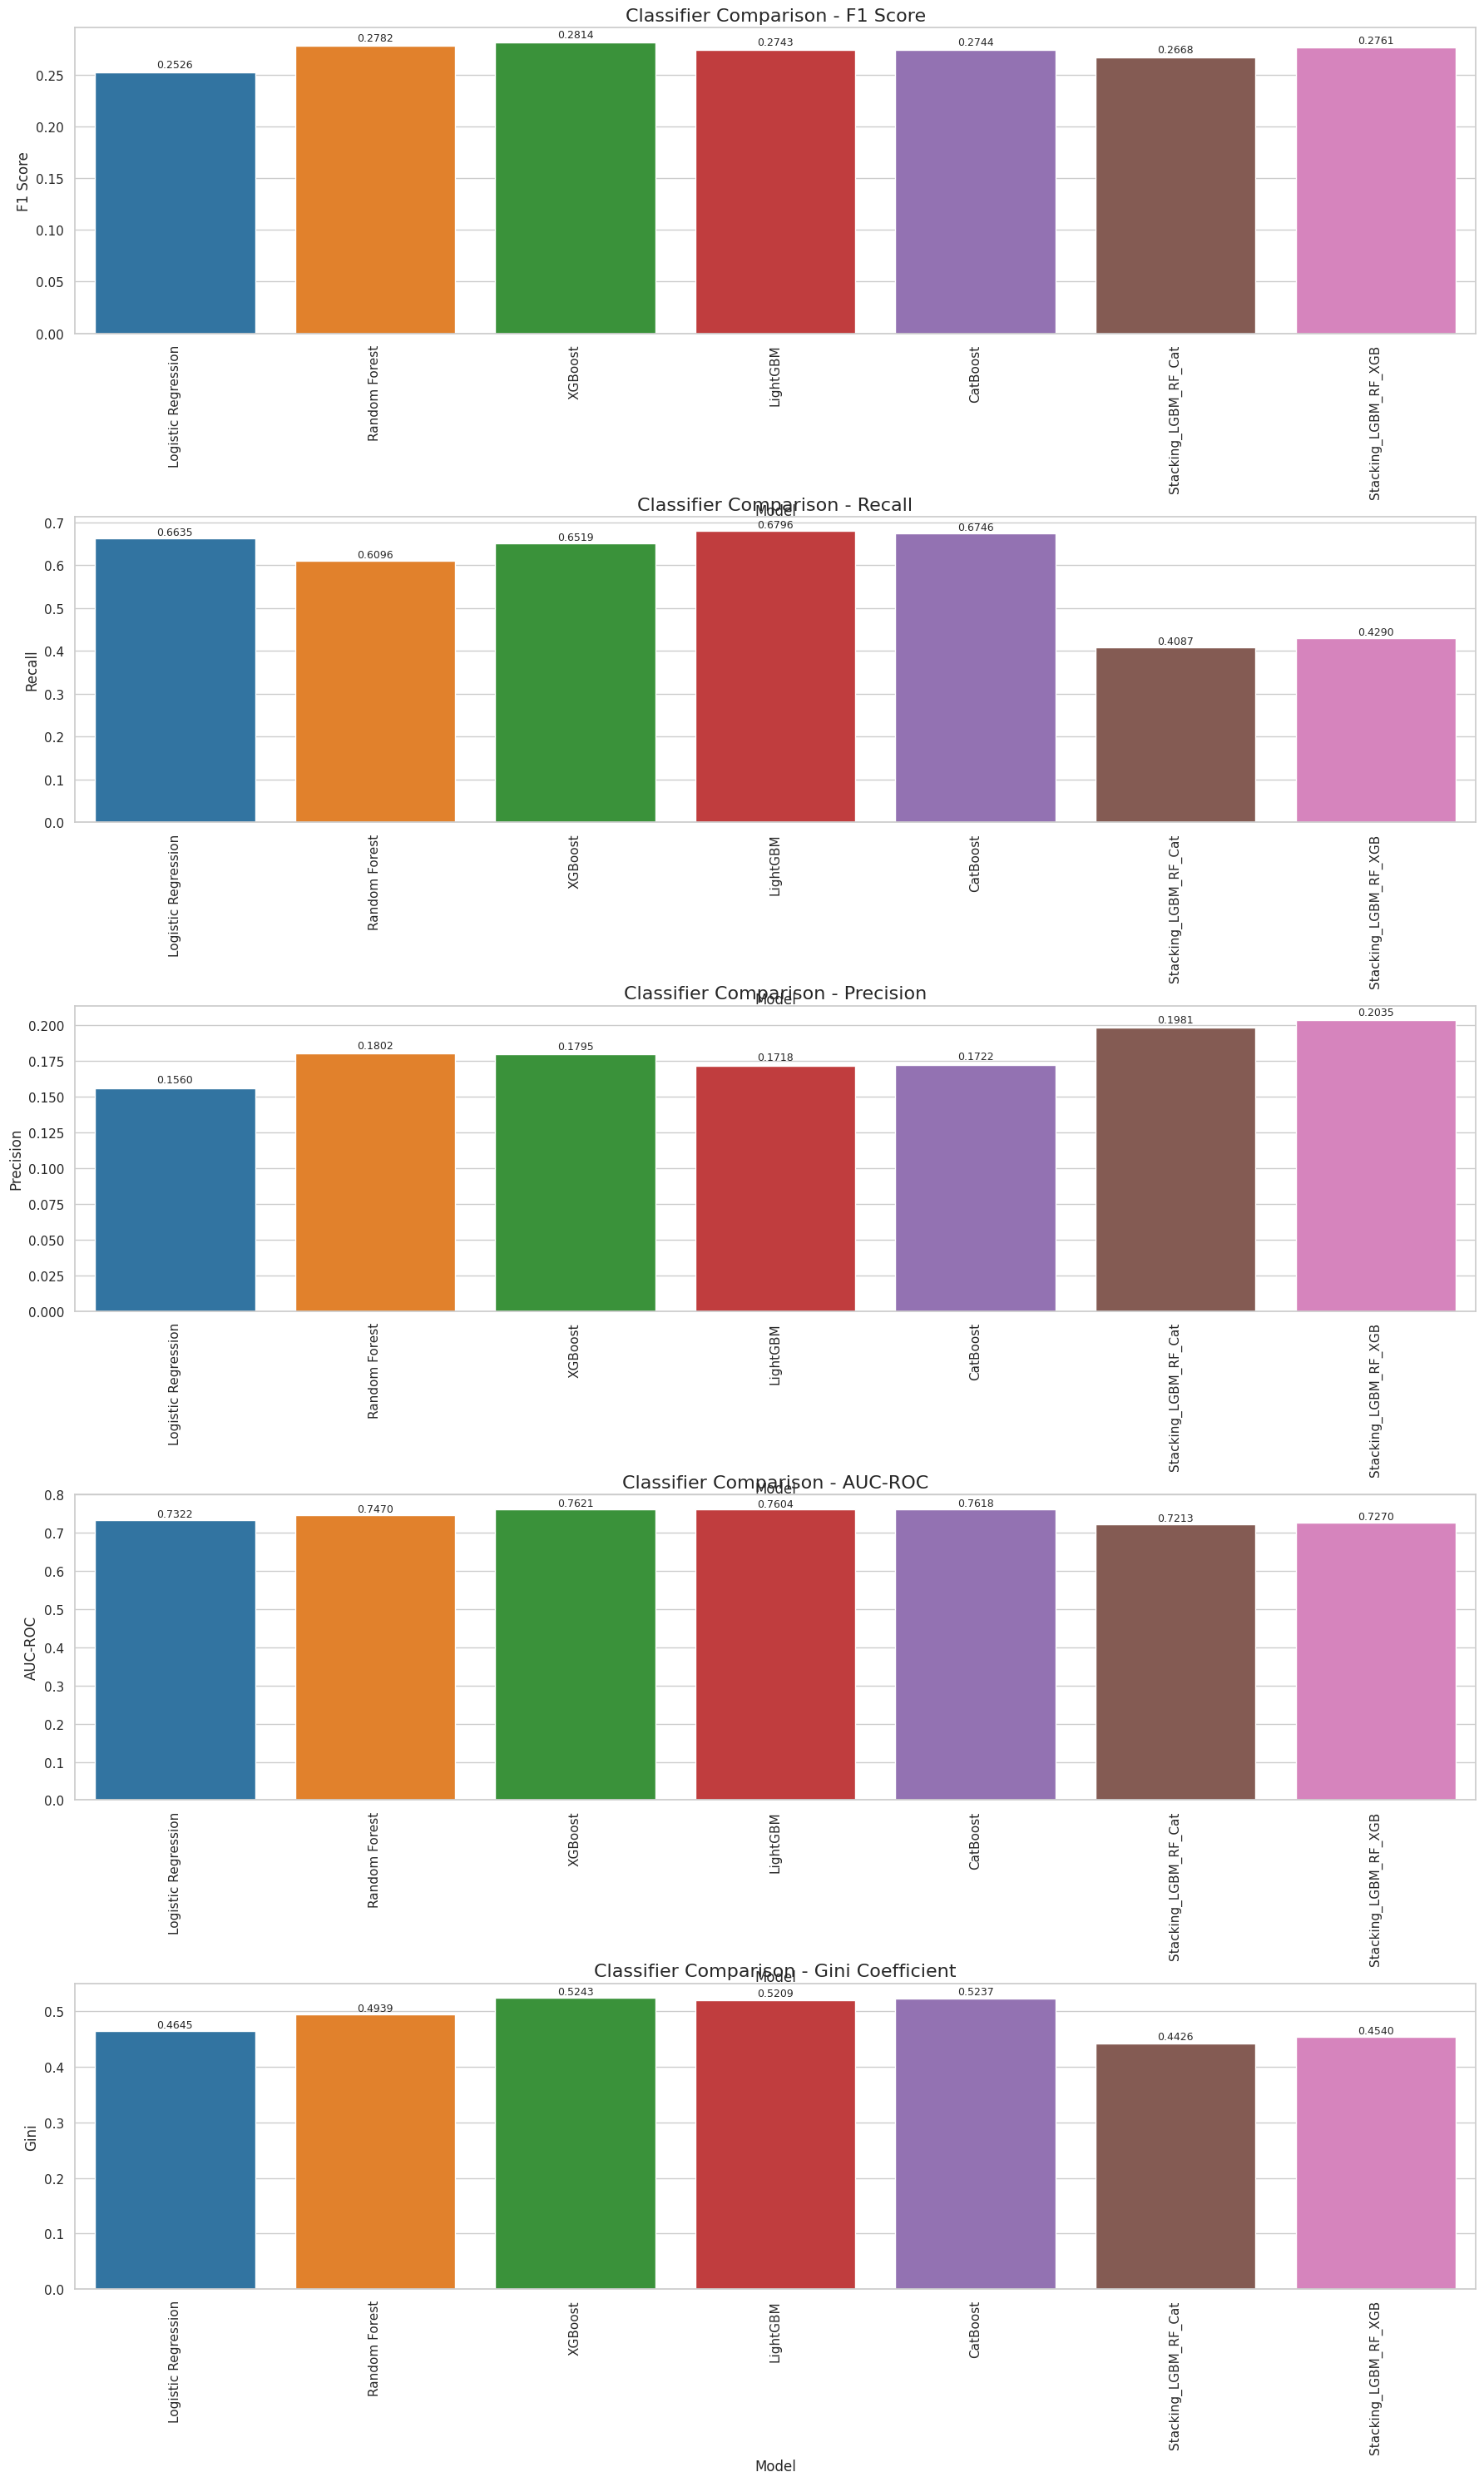

In [ ]:
# Palette màu riêng biệt cho từng model
palette = sns.color_palette("tab10", n_colors=len(df_results))

sns.set(style="whitegrid")
plt.figure(figsize=(18, 30))

# Hàm vẽ từng chỉ số
def plot_metric(ax, metric_name, values, title):
    bars = sns.barplot(x=df_results["Model"], y=values, ax=ax, palette=palette)
    ax.set_title(title, fontsize=16)
    ax.set_ylabel(metric_name)
    ax.set_xticklabels(bars.get_xticklabels(), rotation=90)
    for i, v in enumerate(values):
        ax.text(i, v + 0.002, f"{v:.4f}", ha='center', va='bottom', fontsize=9)

# Vẽ từng biểu đồ
ax1 = plt.subplot(511)
plot_metric(ax1, "F1 Score", df_results["F1 Score"], "Classifier Comparison - F1 Score")

ax2 = plt.subplot(512)
plot_metric(ax2, "Recall", df_results["Recall"], "Classifier Comparison - Recall")

ax3 = plt.subplot(513)
plot_metric(ax3, "Precision", df_results["Precision"], "Classifier Comparison - Precision")

ax4 = plt.subplot(514)
plot_metric(ax4, "AUC-ROC", df_results["AUC-ROC"], "Classifier Comparison - AUC-ROC")

ax5 = plt.subplot(515)
plot_metric(ax5, "Gini", df_results["Gini"], "Classifier Comparison - Gini Coefficient")

plt.tight_layout()
plt.subplots_adjust(hspace=0.6)
plt.show()

### Comparing with Best Threshold

In [ ]:
#List best Threshold
logreg_best_threshold = 0.65
rf_best_threshold = 0.58
xgb_best_threshold = 0.64
lgbm_best_threshold = 0.66
catboost_best_threshold = 0.66
best_thresh_catboost_stack = 0.46
best_thresh_xgb_stack = 0.46

In [ ]:
# Danh sách mô hình và threshold đã tối ưu
models_with_thresholds = [
    ("Logistic Regression", logreg_best_model, logreg_best_threshold),
    ("Random Forest", rf_best_model, rf_best_threshold),
    ("XGBoost", xgb_best_model, xgb_best_threshold),
    ("LightGBM", lgbm_best_model, lgbm_best_threshold),
    ("CatBoost", catboost_best_model, catboost_best_threshold),
    ("Stacking_LGBM_RF_Cat", stacking_lgbm_rf_catboost_pipeline,best_thresh_catboost_stack ),
    ("Stacking_LGBM_RF_XGB", stacking_lgbm_rf_xgb_pipeline,best_thresh_xgb_stack )
]

In [ ]:
results = []

for name, model, threshold in models_with_thresholds:
    print(f"Evaluating {name} with threshold {threshold:.2f}")
    X_eval = X_test_raw if isinstance(model, Pipeline) else X_test
    result = evaluate_model_with_threshold(name, model, X_eval, y_test, threshold)
    results.append(result)

# Chuyển sang DataFrame và sắp xếp theo F1 Score
df_best_threshold = pd.DataFrame(results)
df_best_threshold = df_best_threshold.sort_values(by="F1 Score", ascending=False).reset_index(drop=True)

# Hiển thị
display(df_best_threshold)


Evaluating Logistic Regression with threshold 0.65

📊 Evaluation for Logistic Regression with threshold 0.65
F1 Score       : 0.2883
Recall         : 0.4278
Precision      : 0.2174
AUC-ROC        : 0.7322
Gini           : 0.4645
Specificity    : 0.8626
G-Mean         : 0.6074
Confusion Matrix:
[[46100  7343]
 [ 2729  2040]]
Evaluating Random Forest with threshold 0.58

📊 Evaluation for Random Forest with threshold 0.58
F1 Score       : 0.2949
Recall         : 0.4506
Precision      : 0.2192
AUC-ROC        : 0.7470
Gini           : 0.4939
Specificity    : 0.8568
G-Mean         : 0.6213
Confusion Matrix:
[[45788  7655]
 [ 2620  2149]]
Evaluating XGBoost with threshold 0.64

📊 Evaluation for XGBoost with threshold 0.64
F1 Score       : 0.3185
Recall         : 0.4531
Precision      : 0.2456
AUC-ROC        : 0.7621
Gini           : 0.5243
Specificity    : 0.8758
G-Mean         : 0.6300
Confusion Matrix:
[[46804  6639]
 [ 2608  2161]]
Evaluating LightGBM with threshold 0.66

📊 Evaluation for 

,Model,Threshold,F1 Score,Recall,Precision,AUC-ROC,Gini,Specificity,G-Mean
0,XGBoost,0.64,0.318520,0.453135,0.245568,0.762142,0.524285,0.875774,0.629955
1,CatBoost,0.66,0.317652,0.436779,0.249581,0.761849,0.523698,0.882810,0.620961
2,LightGBM,0.66,0.316613,0.441392,0.246834,0.760426,0.520852,0.879816,0.623173
3,Random Forest,0.58,0.294929,0.450619,0.219196,0.746962,0.493925,0.856763,0.621348
4,Logistic Regression,0.65,0.288298,0.427763,0.217414,0.732225,0.464450,0.862601,0.607444
5,Stacking_LGBM_RF_XGB,0.46,0.276308,0.461942,0.197101,0.727012,0.454024,0.832083,0.619979
6,Stacking_LGBM_RF_Cat,0.46,0.267306,0.444118,0.191190,0.721299,0.442597,0.832345,0.607996


### Choose Best Performing Model

In [ ]:
# Select the best model based on a metric, e.g., F1 Score
best_model_row = df_best_threshold.loc[df_best_threshold['F1 Score'].idxmax()]
best_model_name = best_model_row['Model']
best_threshold = best_model_row['Threshold']

# Find the best model object from the list of models with thresholds
best_model = None
for name, model, threshold in models_with_thresholds:
    if name == best_model_name and threshold == best_threshold:
        best_model = model
        best_threshold_for_xai = threshold # Use a different variable name to avoid confusion
        break

# Check if a model was found
if best_model is None:
    print(f"Error: Model '{best_model_name}' with threshold {best_threshold} not found in the models_with_thresholds list.")
else:
    print(f"Selected best model: {best_model_name} with best threshold: {best_threshold_for_xai}")

Selected best model: XGBoost with best threshold: 0.64


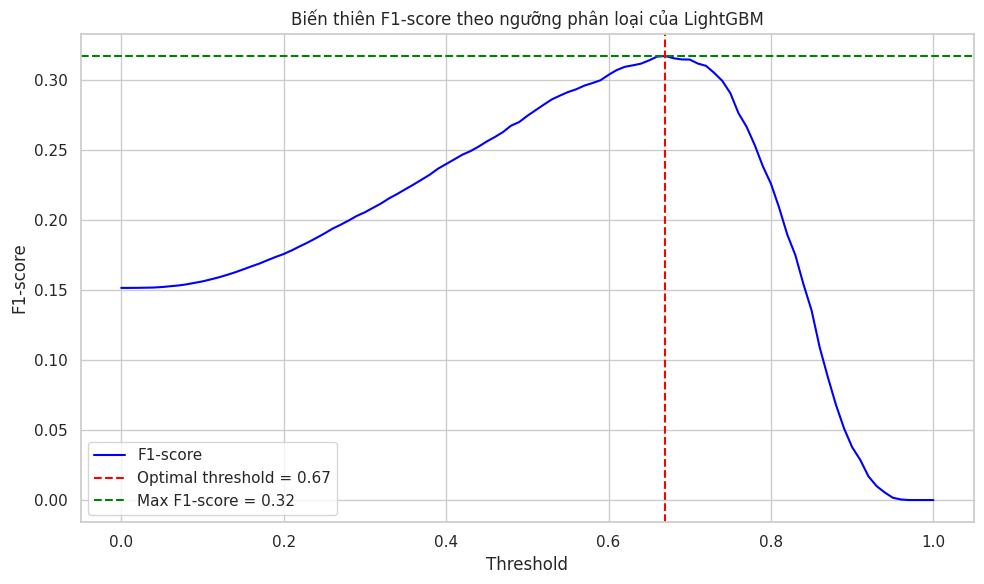

In [ ]:
# Xác suất dự đoán của LightGBM
X_eval = X_test_raw if isinstance(lgbm_best_model, Pipeline) else X_test
y_pred_proba_lgbm = lgbm_best_model.predict_proba(X_eval)[:, 1]

# Dải ngưỡng
thresholds = np.linspace(0.0, 1.0, 101)
f1_scores = []

for t in thresholds:
    y_pred = (y_pred_proba_lgbm >= t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred))

# Tìm ngưỡng tối ưu
optimal_threshold = thresholds[np.argmax(f1_scores)]
max_f1 = np.max(f1_scores)

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores, label="F1-score", color="blue")
plt.axvline(x=optimal_threshold, linestyle="--", color="red", label=f'Optimal threshold = {optimal_threshold:.2f}')
plt.axhline(y=max_f1, linestyle="--", color="green", label=f'Max F1-score = {max_f1:.2f}')
plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.title("Biến thiên F1-score theo ngưỡng phân loại của LightGBM")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Lưu hình
import os
os.makedirs("figures", exist_ok=True) # Create the directory if it doesn't exist
plt.savefig("figures/threshold_f1_lgbm.png", dpi=300)
plt.show()

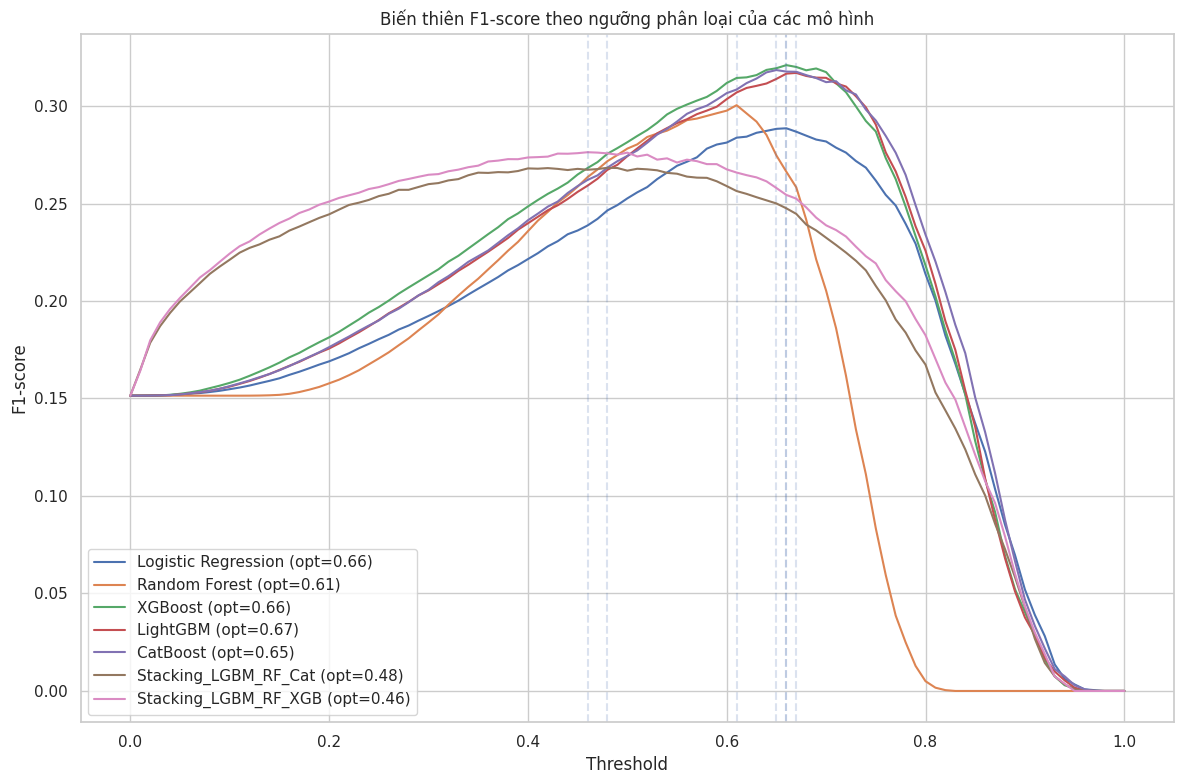

In [ ]:
# Tạo thư mục lưu hình
os.makedirs("figures", exist_ok=True)

# Danh sách mô hình và tên tương ứng
models = {
    "Logistic Regression": logreg_best_model,
    "Random Forest": rf_best_model,
    "XGBoost": xgb_best_model,
    "LightGBM": lgbm_best_model,
    "CatBoost": catboost_best_model,
    "Stacking_LGBM_RF_Cat": stacking_lgbm_rf_catboost_pipeline,
    "Stacking_LGBM_RF_XGB": stacking_lgbm_rf_xgb_pipeline
}

# Khởi tạo dải ngưỡng
thresholds = np.linspace(0, 1, 101)
plt.figure(figsize=(12, 8))

for name, model in models.items():
    # Xử lý nếu model nằm trong pipeline
    X_eval = X_test_raw if hasattr(model, "predict_proba") and isinstance(model, Pipeline) else X_test
    # Dự đoán xác suất
    y_proba = model.predict_proba(X_eval)[:, 1]

    # Tính F1-score theo từng ngưỡng
    f1s = [f1_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]

    # Ghi nhận ngưỡng tối ưu và F1 tương ứng
    opt_idx = np.argmax(f1s)
    optimal_threshold = thresholds[opt_idx]
    max_f1 = f1s[opt_idx]

    # Vẽ đường F1 theo threshold
    plt.plot(thresholds, f1s, label=f"{name} (opt={optimal_threshold:.2f})")
    plt.axvline(optimal_threshold, linestyle="--", alpha=0.2)

# Hoàn thiện biểu đồ
plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.title("Biến thiên F1-score theo ngưỡng phân loại của các mô hình")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/threshold_f1_all_models.pdf", dpi=300)
plt.show()

In [ ]:
# Khởi tạo dải ngưỡng
thresholds = np.linspace(0, 1, 101)

# Lưu kết quả vào list
results = []

for name, model in models.items():
    # Xử lý nếu model nằm trong pipeline
    X_eval = X_test_raw if hasattr(model, "predict_proba") and isinstance(model, Pipeline) else X_test
    # Dự đoán xác suất
    y_proba = model.predict_proba(X_eval)[:, 1]

    # Tính F1 theo từng ngưỡng
    f1s = [f1_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]

    # Tìm ngưỡng tối ưu
    opt_idx = np.argmax(f1s)
    optimal_threshold = thresholds[opt_idx]
    max_f1 = f1s[opt_idx]

    # Lưu kết quả
    results.append({
        "Model": name,
        "Optimal Threshold": round(optimal_threshold, 2),
        "Best F1-score": round(max_f1, 4)
    })

# Tạo bảng DataFrame
threshold_table = pd.DataFrame(results)
print(threshold_table)

# Xuất ra file LaTeX nếu muốn
threshold_table.to_latex("figures/optimal_threshold_table.tex", index=False)

                  Model  Optimal Threshold  Best F1-score
0   Logistic Regression               0.66         0.2886
1         Random Forest               0.61         0.3004
2               XGBoost               0.66         0.3210
3              LightGBM               0.67         0.3170
4              CatBoost               0.65         0.3184
5  Stacking_LGBM_RF_Cat               0.48         0.2683
6  Stacking_LGBM_RF_XGB               0.46         0.2763
